## CS440 Assignment 3
Transformers for Retrieval and Translation

**Deadline:** November 24, 2026 at 10:00 PM Eastern Time. **Total:** 100 points. Teams may have up to four members. Submit one `hw3.ipynb` per team on Gradescope and add all members. Late submissions receive 0 points. Read HW3.pdf for the instructions and integrity policy.

### Setup
Run `setup.sh` and select the CS440 HW3 kernel. Use Python 3.12 and CPU PyTorch 2.14.1. Save before `check()`, which loads your saved code and answers and checks their formats.

In [1]:
from pathlib import Path
import sys
# Run from the extracted starter directory. Data is included.
sys.path.insert(0, str(Path("code").resolve()))
from hw3lib.runtime import torch, nn, np, configure
from hw3lib.attention import BookAttention
from hw3lib.notebook import check, load_submission
configure(440)
print("PyTorch", torch.__version__, "CPU threads", torch.get_num_threads())

PyTorch 2.14.1 CPU threads 1


### Problem 1 (50 points)

<div style="max-width:800px">

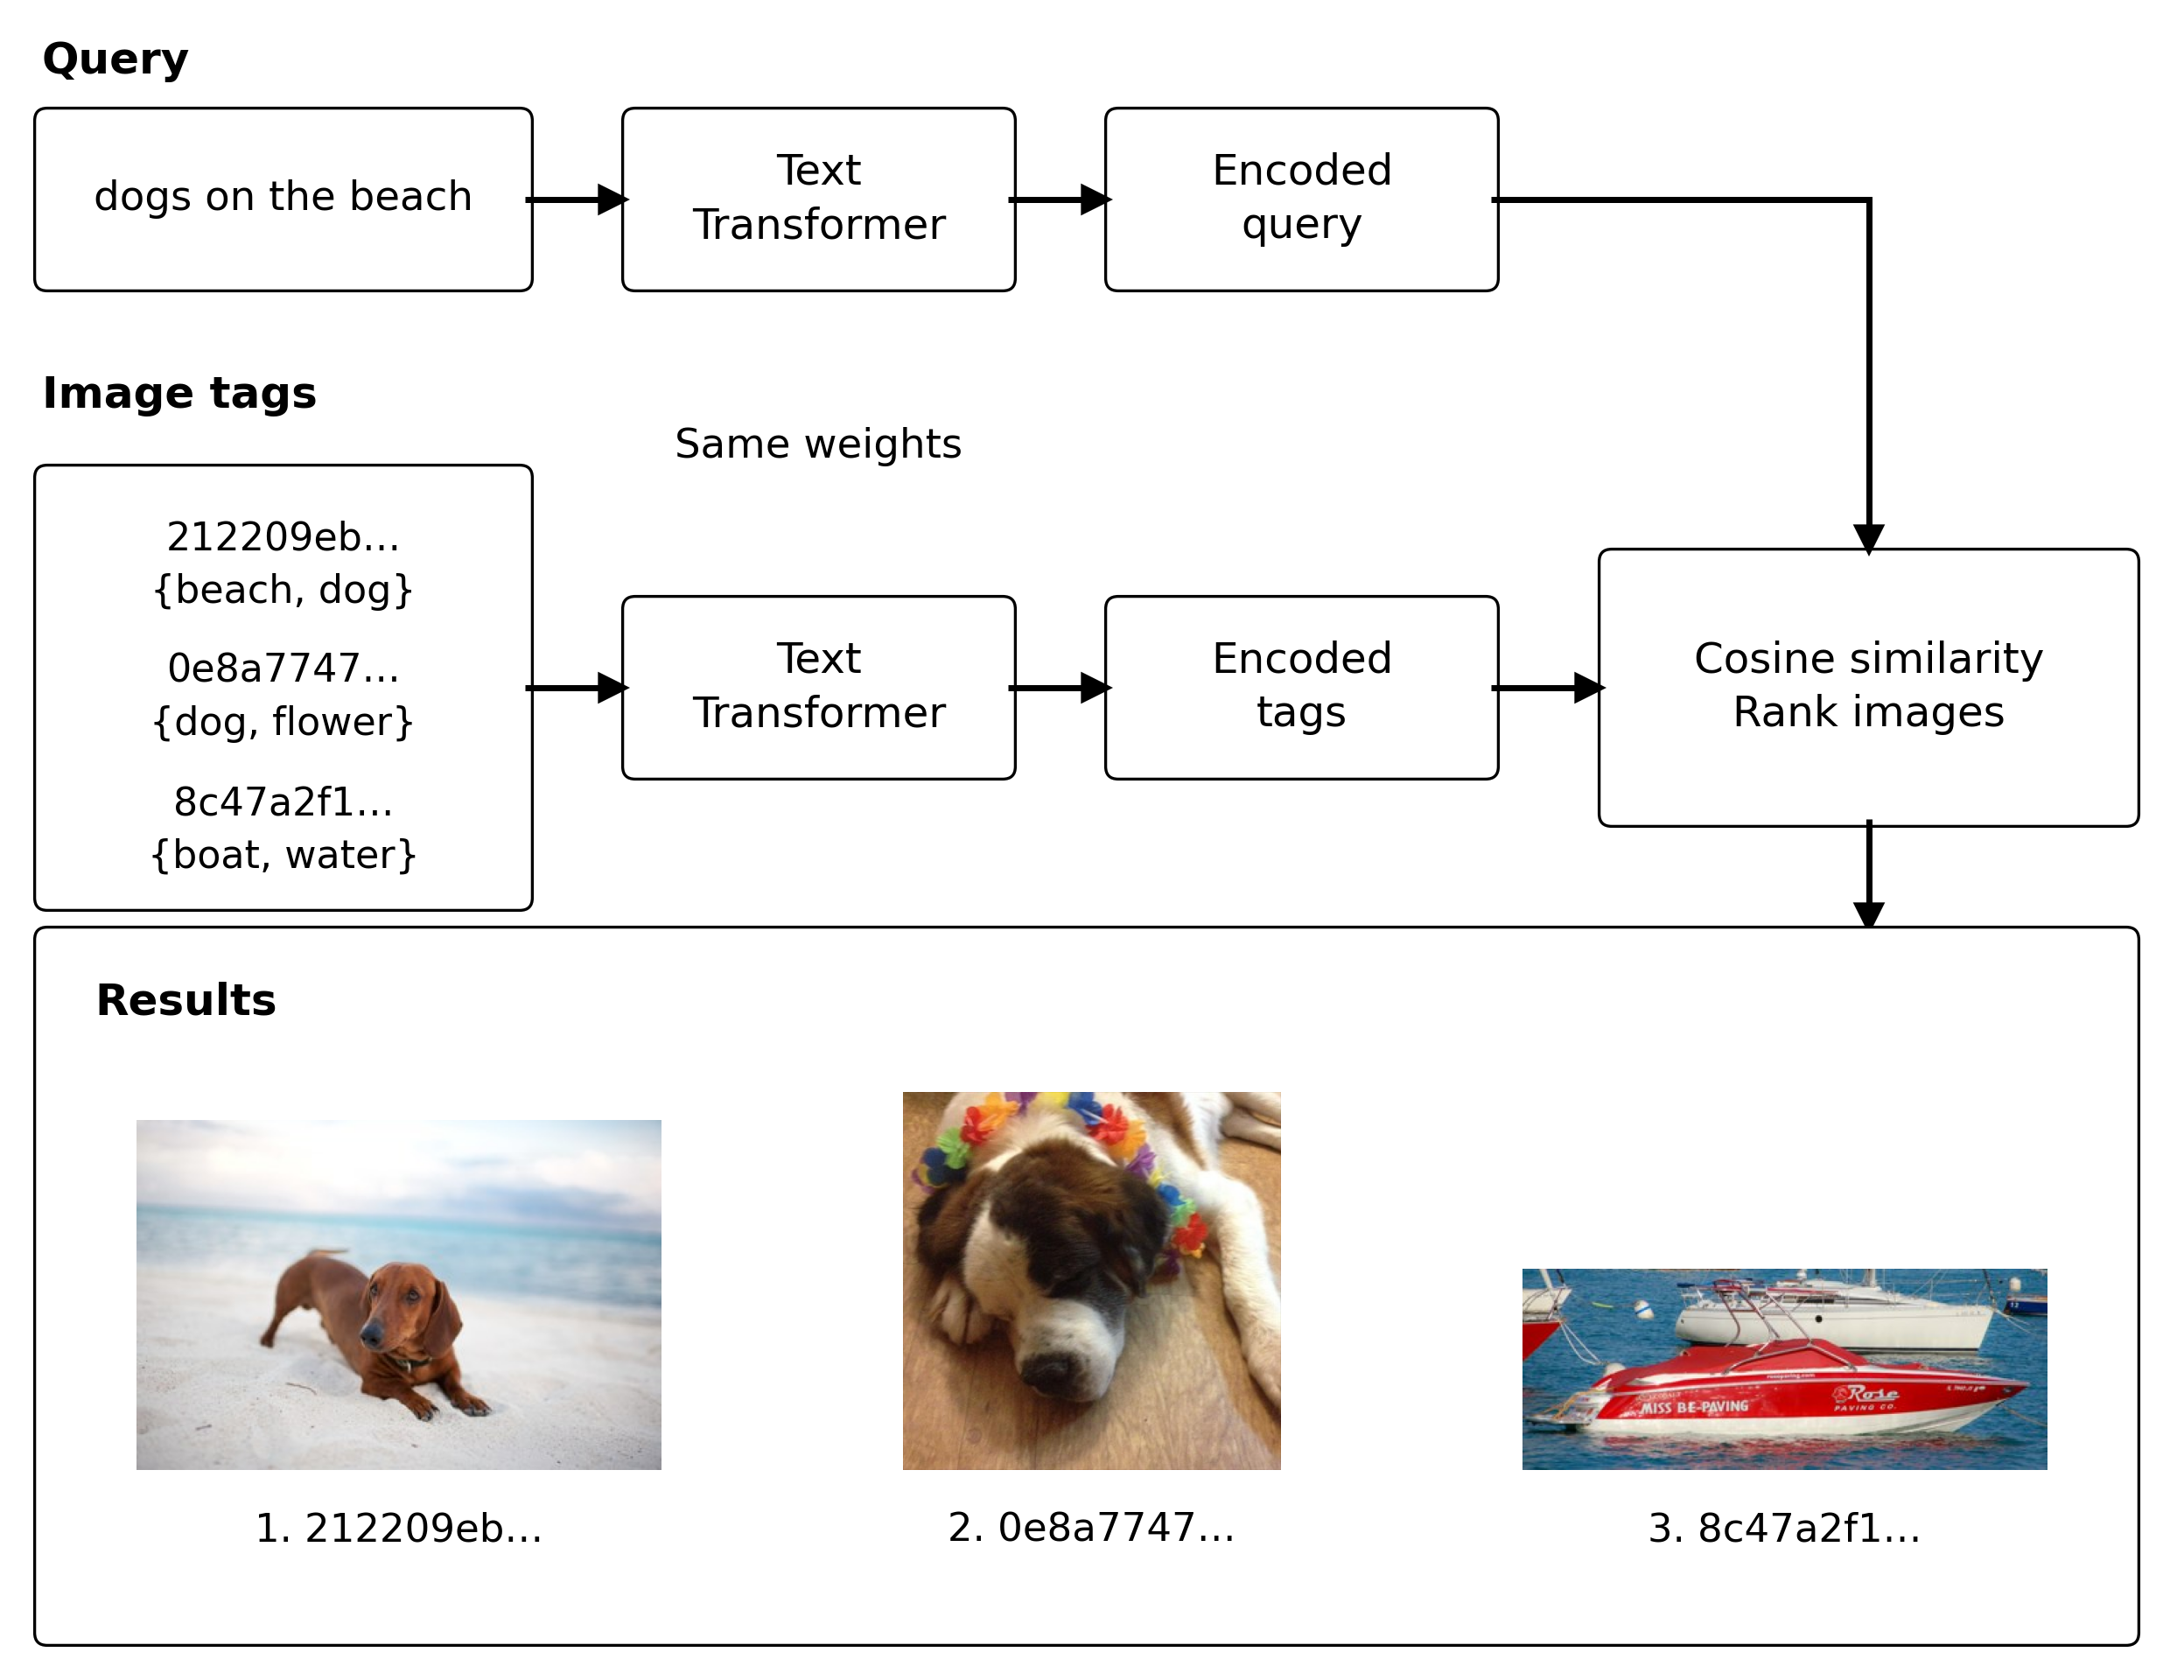

</div>

**Figure 1. Image retrieval.** Example ranking. Photos ([CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), resized): [ToddonFlickr, “0174”](https://www.flickr.com/photos/toddneville/3497407627), [buyalex, “Piccard got lei’d and now he’s tired.”](https://www.flickr.com/photos/buyalex/9792565144), and [pulaw, `_MG_0371`](https://www.flickr.com/photos/pulaw/7182648693/). Full records are in catalog.json.

Encode query text and image tags with the same Transformer. The display helper looks up photos using ranked IDs. A photo may show objects that are missing from its tag list.

#### Positions (8 points)
Complete `forward` and `compute_mask` using learned token and position embeddings. See Problem 1(a).

In [2]:
# GRADED: code
# Adapted from François Chollet's second edition listings (MIT).
# Copyright 2017-present François Chollet. See sources/CHOLLET-CODE-LICENSE.txt.
from hw3lib.runtime import torch,nn,np
from hw3lib.attention import BookAttention

#helps transformer understand what each word means and where it is in the sequence.
class PositionalEmbedding(nn.Module):
    """Book 11.24: learned token+position vectors. IDs long (B,T). pad0/OOV1.
    1<=T<=sequence_length. IDs in [0,vocab_size). Return (B,T,D).
    compute_mask returns bool IDs!=0. Keep the supplied constructors.
    """
    def __init__(self,sequence_length,vocab_size,embed_dim):
        super().__init__();self.sequence_length=sequence_length
        self.token_embeddings=nn.Embedding(vocab_size,embed_dim)
        self.position_embeddings=nn.Embedding(sequence_length,embed_dim)
        nn.init.uniform_(self.token_embeddings.weight,-.05,.05)
        nn.init.uniform_(self.position_embeddings.weight,-.05,.05)
    #This func
    def forward(self,inputs): 
        # BEGIN TODO positions
        #token embeddings are learned representations of the input tokens
        # position embeddings are learned representations of the position of each token in the sequence. 
        # The sum of these two embeddings is used as the input to the transformer model.
        tokenvec = self.token_embeddings(inputs) #convert each words ID into a numerical vector so that the model can understand it
        pos_ids = torch.arange(inputs.shape[1]) # create position numbers from 0 to T-1
        pos_vectors = self.position_embeddings(pos_ids) #convert position indices into learned position vectors so model can understand word order
        return tokenvec + pos_vectors # return the sum of token and position vectors
        # END TODO
    def compute_mask(self,inputs):
        # BEGIN TODO token_mask
        return inputs.ne(0) # create a mask for padding tokens --> returns True for non-padding tokens and False for padding tokens
        # END TODO



#### Encoder (12 points)
Apply attention and FF with residual additions and postnormalization. See Problem 1(b).

In [3]:
# GRADED: code
class TransformerEncoder(nn.Module):
    """Book 11.21: attention -> residual postnormalization -> FF -> residual postnormalization.
    inputs float (B,T,D). mask bool (B,T), True=valid key, or None.
    Return (B,T,D). use supplied attention/dense_proj/layernorm_1/2.
    BookAttention head_dim=D. LayerNorm eps=1e-3. No dropout.
    """
    def __init__(self,embed_dim,dense_dim,num_heads):
        super().__init__()
        self.attention=BookAttention(embed_dim,num_heads)
        self.dense_proj=nn.Sequential(nn.Linear(embed_dim,dense_dim),nn.ReLU(),nn.Linear(dense_dim,embed_dim))
        self.layernorm_1=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_2=nn.LayerNorm(embed_dim,eps=1e-3)
    def forward(self,inputs,mask=None):
        # BEGIN TODO encoder
        #Attention expects a (B, query, key) mask.
        #Adding a dimension lets the same valid-key mask
        #apply to every word asking for attention.
        if mask is not None: # if a mask is provided we need to format it to match the expected dimensions for the attention mechanism
            mask = torch.unsqueeze(mask, 1) # add a singleton dimension for broadcasting

        #Query (what info word is looking for) Key (what info each word offer for matching) Value (what info to collect from each word) all come from inputs.
        #Each word compares itself with the others to decide which words are useful for updating its representation.
        #The mask prevents using padding as meaningful context.
        attention_op = self.attention(inputs, inputs, inputs, attention_mask=mask)

        #Add the original input so attention doesn't replace the word's existing information completely
        # Normalize afterward to keep values in a reasonable range and avoid exploding/vanishing gradients.
        U = self.layernorm_1(inputs + attention_op) 

        #attention mixes information from other words
        #but we also want to allow each word to update itself independently
        #therefore, we use a feedforward network to let each word process its information.
        feedforward_output = self.dense_proj(U)

        #keep info from U while adding feeed forward output amd normalize again
        Y = self.layernorm_2(U + feedforward_output)

        return Y # return the final output of the transformer encoder
        # END TODO



#### Retriever (10 points)
Encode valid tokens, pool their vectors, and normalize the result. See Problem 1(c).

In [4]:
# GRADED: code
class TextRetriever(nn.Module):
    """Shared Transformer encodes queries and CANONICAL tag strings.
    tokens long (B,T), pad0/OOV1. Return float (B,D). Supplied catalog helper
    sorts/deduplicates tags BEFORE vectorization. query order is preserved.
    Pool = sum(valid*h)/max(count,1). output=pool/max(||pool||2,1e-8).
    All pad -> exact zero, trailing pads must not change embeddings.
    """
    def __init__(self,vocab_size,sequence_length=20,embed_dim=32,dense_dim=64,num_heads=2):
        super().__init__()
        self.embedding=PositionalEmbedding(sequence_length,vocab_size,embed_dim)
        self.encoder=TransformerEncoder(embed_dim,dense_dim,num_heads)
    def forward(self,tokens):
        # BEGIN TODO retriever
        # Identify which tokens are valid (non-padding): True for real words, False for padding ID 0
        # Built directly from the token IDs so the pooling does not depend on the embedding layer
        mask = tokens != 0

        emb_tokens = self.embedding(tokens) # Convert token IDs into embeddings that include both token/word + positional information

        # now we have the embeddings for each token in the sequence
        # we can pass them through the transformer encoder to get representations of each token that consider the context of the other tokens in the sequence
        encoder_out = self.encoder(emb_tokens, mask=mask)

        # Add a dimension to the mask so it matches the shape of the encoder outputs (B,T,1)
        expanded_mask = mask.unsqueeze(-1)

        # Replace padded positions with exact zeros using torch.where instead of multiplying by the mask,
        # because inf*0 and nan*0 give nan, so padding could still leak into the result
        valid_vectors = torch.where(expanded_mask, encoder_out, torch.zeros_like(encoder_out))

        # Add all real word vectors together ignoring padding 
        # This is the first step in averaging the words into one vector representing the entire sentence.
        maskedsum = torch.sum(valid_vectors, dim=1)

        # Count the number of valid (non-padding) tokens for each sequence in the batch
        valid_counts = torch.clamp_min(torch.sum(mask, dim=1, keepdim=True), 1)

        u = maskedsum / valid_counts # Average the sum of valid word vectors by the count of valid tokens to get a single vector representation for each sequence in the batch

        # Calculate L2 norm with minimum denominator 1e-8
        norms = torch.linalg.vector_norm(
            u, ord=2, dim=1, keepdim=True
        ).clamp_min(1e-8)

    
        # normalize the vector by dividing by the normalization factor
        # z is essentially the final output of the TextRetriever, which is a batch of normalized vector representations for each input sequence
        z = u / norms 

        return z
        # END TODO



#### Ranking (10 points)
Return catalog indices and cosine scores with stable ID ordering for ties. See Problem 1(d).

In [5]:
# GRADED: code
def retrieve_topk(query_vectors,key_vectors,image_ids,k):
    """Return (indices,scores), each (Q,k), into original catalog order.
    Finite float vectors (Q,D),(N,D). unique string IDs length N. 1<=k<=N.
    cosine=dot(q/max(||q||,1e-8),key/max(||key||,1e-8)). zero vectors score0.
    Sort by (-cosine,image_id) using EXACT ties, lexicographic string IDs.
    No rounding/tolerance buckets. No input mutation. NumPy allowed here.
    Tensor/ndarray returns accepted. Inputs CPU tensors or NumPy arrays.
    """
    # BEGIN TODO ranking
    # Convert inputs to NumPy arrays 
    queries = np.asarray(query_vectors)
    keys = np.asarray(key_vectors)

    # Calculate the L2 norms of the query and key vectors along the last axis (D) to prepare for normalization
    q_norms = np.linalg.norm(queries, axis=1, keepdims=True)
    k_norms = np.linalg.norm(keys, axis=1, keepdims=True)

    # Normalize vectors (avoid division by zero)
    normalizedQ = queries / np.maximum(q_norms, 1e-8)
    normalizedK = keys / np.maximum(k_norms, 1e-8)

    # Compute cosine similarity scores
    # the @ operator performs matrix multiplication
    # which in this case computes the dot product between each query vector and each key vector
    # this then results in a matrix of cosine similarity scores
    cosine = normalizedQ @ normalizedK.T

    #Store the ranked image positions and their scores
    all_indices = []
    all_scores = []

    # Rank each query's scores
    for scores in cosine:
        #sort images by highest cosine similarity score first
        # in case of ties sort alphabetically by image IDs
        sorted_indices = sorted(range(len(image_ids)), key=lambda i: (-scores[i], image_ids[i]))

        top_indices = sorted_indices[:k] # select the top k indices based on the sorted order

        top_scores = scores[top_indices] # get similarity scores for the top k indices

        all_indices.append(top_indices) # add the top k indices for this query to the list of all indices

        all_scores.append(top_scores) # add the top k scores for this query to the list of all scores

    return np.array(all_indices), np.array(all_scores) #return ranked indices and their corresponding similarity scores as NumPy arrays
    # END TODO



#### Questions (10 points)
Use the complete prompts and options in HW3.pdf.

| Variable | Points | PDF item |
|:---|---:|:---|
| `Q1_FIGURE_SCORES` | 3 | 1(e)1 |
| `Q1_TIED_IDS` | 1 | 1(e)2 |
| `Q1_PROBABILITIES` | 2 | 1(e)3 |
| `Q1_PAYLOAD` | 2 | 1(e)4 |
| `Q1_SYNONYM` | 2 | 1(e)5 |

In [6]:
# GRADED: answers
Q1_FIGURE_SCORES= [0.5, 1.0, 0.5]
Q1_TIED_IDS = ["A", "C"]
Q1_PROBABILITIES = "B"
Q1_PAYLOAD = "C"
Q1_SYNONYM = "B"


### Problem 2 (50 points)

<div style="max-width:800px">

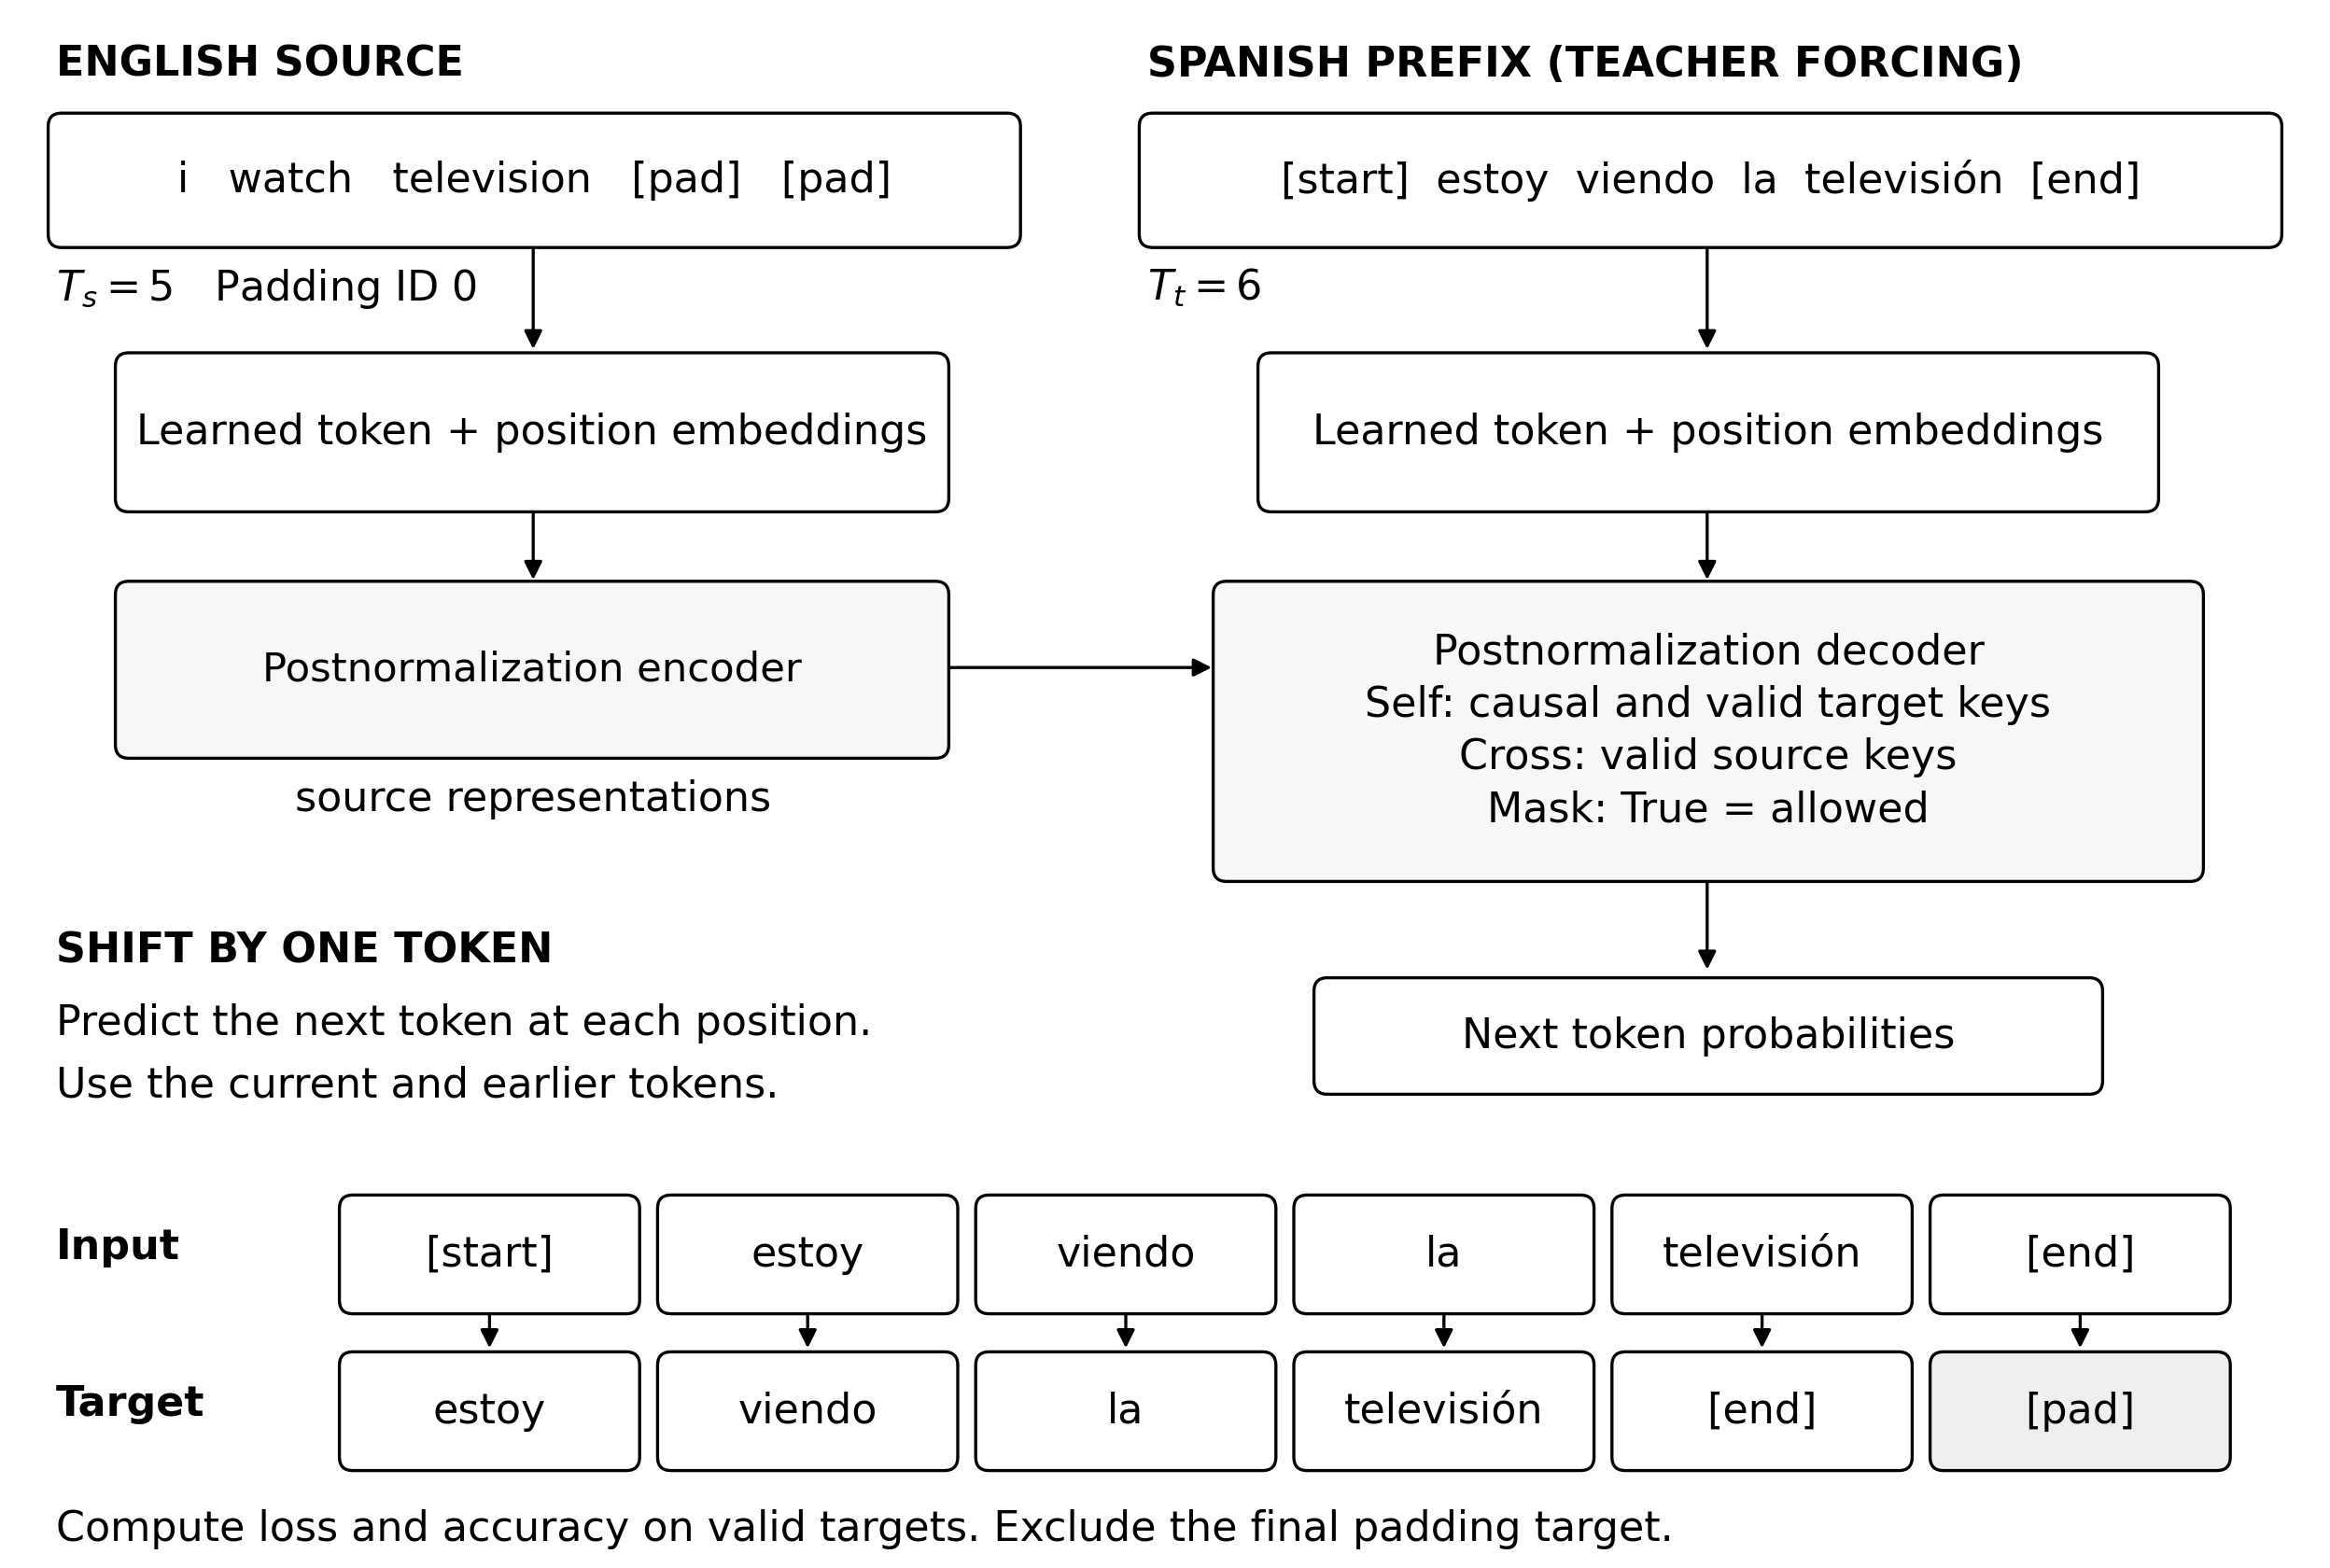

</div>

**Figure 2. English to Spanish translation.** Teacher forcing for the validation pair “I watch television.” → “Estoy viendo la televisión.” ManyThings and Tatoeba contributors, CC BY 2.0 FR.

Use the supplied encoder and decoder model to translate English to Spanish. Follow the mask definitions and metric equations in the handout.

#### Masks (10 points)
Build boolean encoder, self attention and cross attention masks. True means allowed. See Problem 2(a).

In [7]:
# GRADED: code
def build_attention_masks(encoder_tokens,decoder_tokens):
    """Return (encoder_mask,self_mask,cross_mask), bool True=allowed.
    long inputs (B,Ts),(B,Tt), pad0. Ts,Tt>=1, every source has nonpad.
    Encoder (B,1,Ts): source key!=0. Self (B,Tt,Tt): j<=i AND tgt key!=0.
    Cross (B,Tt,Ts): source key!=0, NO causality. Query padding need not
    be zeroed. masked loss ignores pad targets. Unequal Ts,Tt supported.
    """
    # BEGIN TODO masks

    # get number of sequences in the batch (B) 
    # and the lengths of the encoder and decoder sequences (Ts and Tt)
    B, Ts = encoder_tokens.shape
    _, Tt = decoder_tokens.shape

    # Allows attention to real English words but not padding.
    # unsqueeze adds dimension for broadcasting so that the mask can be applied to all attention heads in the multi-head attention mechanism.
    encoder_mask = (encoder_tokens != 0).unsqueeze(1)

    # Decoder self-attention: causal + non-padding target keys
    # Creates a lower-triangular mask so each Spanish word
    # can only look at itself and earlier Spanish words --> prevents the model from cheating by seeing future words.
    causal_mask = torch.tril(
        torch.ones(
            Tt, Tt,
            dtype=torch.bool,
            device=decoder_tokens.device
        )
    )

    # Create a mask for valid target tokens (non-padding)
    validTarget = (decoder_tokens != 0).unsqueeze(1)

    # Combine the causal mask and the valid target mask to create the self-attention mask
    selfattention_mask = causal_mask.unsqueeze(0) & validTarget

    # Cross-attention: allow all non-padding source keys
    # allows each spanish word to look at ALL the real english words
    # Unlike self-attention there is no future word restriction
    # because the entire English sentence is already available
    crossattention_mask = (encoder_tokens != 0).unsqueeze(1).expand(B, Tt, Ts)

    return encoder_mask, selfattention_mask, crossattention_mask # return the three attention masks for encoder, self-attention, and cross-attention
    # END TODO



#### Decoder (15 points)
Apply self attention, source cross attention and FF in sequence with postnormalization. See Problem 2(b).

In [8]:
# GRADED: code
class TransformerDecoder(nn.Module):
    """Book 11.33-11.35, explicit mask routing. inputs (B,Tt,D),
    encoder_outputs (B,Ts,D). self_mask bool (B,Tt,Tt), cross_mask (B,Tt,Ts),
    True=allowed. either may be None. Three residual postnormalization sublayers:
    self attention, source cross attention, FF. Return (B,Tt,D).
    BookAttention head_dim=D, LayerNorm eps=1e-3. Constructors supplied.
    """
    def __init__(self,embed_dim,dense_dim,num_heads):
        super().__init__()
        self.attention_1=BookAttention(embed_dim,num_heads)
        self.attention_2=BookAttention(embed_dim,num_heads)
        self.dense_proj=nn.Sequential(nn.Linear(embed_dim,dense_dim),nn.ReLU(),nn.Linear(dense_dim,embed_dim))
        self.layernorm_1=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_2=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_3=nn.LayerNorm(embed_dim,eps=1e-3)
    def get_causal_attention_mask(self,inputs):
        b,t,_=inputs.shape;a=torch.arange(t,device=inputs.device)
        return (a[:,None]>=a[None,:])[None,:,:].expand(b,-1,-1)
    def forward(self,inputs,encoder_outputs,self_mask=None,cross_mask=None):
        # BEGIN TODO decoder
        # Self-attention = prevents future word usage
        # spanish tokens look at themselves and earlier spanish tokens to understand context
        attention_output1 = self.attention_1(
            inputs, inputs, inputs,
            attention_mask=self_mask
        )

        # add og spanish token embeddings to the self-attention output and normalize
        out_one = self.layernorm_1(inputs + attention_output1)

        # Cross-attention with encoder outputs
        # allows each spanish word to look at ALL the real english words
        # Unlike self-attention there is no future word restriction
        # because the entire English sentence is already available
        attention_output2 = self.attention_2(
            out_one, encoder_outputs, encoder_outputs,
            attention_mask=cross_mask
        )

        # add the output of the self-attention layer to the output of the cross-attention layer and normalize
        # keeping spanish representation while adding in the english context
        out_two = self.layernorm_2(out_one + attention_output2)

        # Feed-forward network
        # transform each spanish token representation independently to allow for more complex transformations
        feedforward_output = self.dense_proj(out_two)

        # add feed foward output now
        out_three = self.layernorm_3(
            out_two + feedforward_output
        )

        return out_three
        # END TODO



#### Metrics (10 points)
Compute token loss and accuracy using only valid targets. Preserve loss gradients. See Problem 2(c).

In [9]:
# GRADED: code
def masked_token_metrics(targets,probabilities):
    """Return (loss,accuracy), 0-D float tensors. differentiable loss.
    targets long (B,T), normalized finite probability rows (B,T,V).
    m=(targets!=0). loss=sum(-log(clip(p_true,1e-7,1-1e-7))*m)/sum(m).
    acc=sum((argmax(p)==targets)*m)/sum(m). Allpad -> (0,0) with finite
    backward gradients. OOV1 counts. denominator counts valid tokens only.
    """
    # BEGIN TODO metrics

    # mark real target words as 1 and padding as 0
    # this mask will be used to ignore padding tokens when calculating loss and accuracy
    mask = (targets != 0).float()

    # find probability assigned to each correct word at each position
    # so we can see how well the model is predicting the correct words
    p_true = probabilities.gather(
        dim=2,
        index=targets.unsqueeze(-1)
    ).squeeze(-1)

    # calc how wrong the model is for each token by taking the
    # negative log of the probability assigned to the correct token
    loss = -torch.log(
        p_true.clamp(1e-7, 1 - 1e-7)
    )

    # Count real target words excluding padding.
    # .clamp_min(1) ensures we don't divide by zero in case all tokens are padding
    valid = mask.sum().clamp_min(1)

    loss = (loss * mask).sum() / valid #adds up the loss for all valid tokens and divides by the number of valid tokens to get the average loss per valid token

    # Choose the word with the highest predicted probabilityat each position
    predictions = probabilities.argmax(dim=-1)

    # Calculate accuracy by comparing the predicted token IDs with the actual target token IDs 
    # because we want to see how many of the model's predictions match the actual target tokens
    correct = (predictions == targets).float()

    accuracy = (correct * mask).sum() / valid # calculates the accuracy by counting how many of the model's predictions match the actual target tokens, ignoring padding tokens, and dividing by the number of valid tokens

    return loss, accuracy

    # END TODO



#### Greedy decoding (10 points)
Generate a token sequence using the prefix buffer and the stopping rules. See Problem 2(d).

In [10]:
# GRADED: code
def greedy_decode(model,source_tokens,start_id,end_id,max_length):
    """One source long (1,Ts). returns list[int]. CPU inputs/model.
    Model signature: model(source_tokens,decoder_tokens)->probs (1,L,V).
    Allocate zero long decoder buffer (1,L), start in slot0. At step i,
    argmax probs[0,i] (lowest ID tie). end OR pad0 stops without appending.
    Else append and copy to buffer[0,i+1] if space remains. At most L steps.
    Exclude initial start/terminating end/pad. a later emitted start is an
    ordinary generated token. Use model.eval() + no_grad, restore original
    model.training flag even on error. Do not mutate source/model parameters.
    Valid: L>=1, positive distinct start/end IDs, source has nonpad.
    """
    # BEGIN TODO greedy
    # Create fix sized space for the decoder tokens, initialized to zero (padding token ID)
    # This buffer will hold the generated tokens as we decode the sequence one token at a time.
    decoderTokens = torch.zeros(
        (1, max_length),
        dtype=torch.long
    )
    # Set the first token in the decoder buffer to the start token ID
    decoderTokens[0, 0] = start_id

    # Store generated tokens
    generated = []

    # check the original training mode of the model so we can restore it later
    # this is important because we want to make sure that the model is in evaluation mode during decoding
    # but we also want to return it to its original state afterward
    training = model.training

    #now we can start generating tokens one at a time
    try:
        model.eval() # set the model to evaluation mode so that it doesn't update its parameters during decoding

        with torch.no_grad(): # disable gradient calculation to save memory and computation since we are not training the model
            for i in range(max_length): # loop through each position in the decoder buffer up to the maximum length

                # Predict probabilities for all positions
                # Give the model the English sentence and Spanish words generated so far
                # returns probabilities for possible words.
                prob = model(source_tokens, decoderTokens)
                
                # At position i choose the word with highest prob
                # This is greedy decoding because we always choose the best immediate option.
                next = int(
                    prob[0, i].argmax().item()
                )

                # Stop on end token or padding
                if next == end_id or next == 0:
                    break

                # save the generated token to the list of generated tokens
                generated.append(next)

                # Update buffer if space remains 
                if i + 1 < max_length:
                    decoderTokens[0, i + 1] = next

    finally:
        # Restore original training mode 
        model.train(training)

    return generated
    # END TODO


#### Questions (5 points)
Use the complete prompts and options in HW3.pdf.

| Variable | Points | PDF item |
|:---|---:|:---|
| `Q2_SHIFT` | 2 | 2(e)1 |
| `Q2_MASK` | 1 | 2(e)2 |
| `Q2_ACCURACY` | 1 | 2(e)3 |
| `Q2_POSITIONS` | 1 | 2(e)4 |

In [11]:
# GRADED: answers
Q2_SHIFT = [4, 7, 2, 0]
Q2_MASK = "C"
Q2_ACCURACY = "A"
Q2_POSITIONS = "B" 


In [12]:
check()

PASS positions
PASS encoder
PASS retriever
PASS ranking
PASS masks
PASS decoder
PASS metrics
PASS greedy
PASS Answer formats
Format checks finished.


True

### Examples (optional)
Set `RUN_DEMOS=True` to train the examples. Inspect the retrieval results and compare generated translations with their references. The helpers load your saved definitions.

{'loss': [0.8175915119022811, 0.1316165975037149, 0.07106542431351999, 0.05015522799779227, 0.044089921619682435, 0.039687557422012965, 0.03627584658635944, 0.034514508037206015, 0.03231782631809044, 0.030729034351312377, 0.028605709598681826, 0.028322788325505457], 'seconds': 0.4723354169400409, 'seed': 440, 'epochs': 12, 'training_source': 'Catalog tags and supplied paraphrases.'}


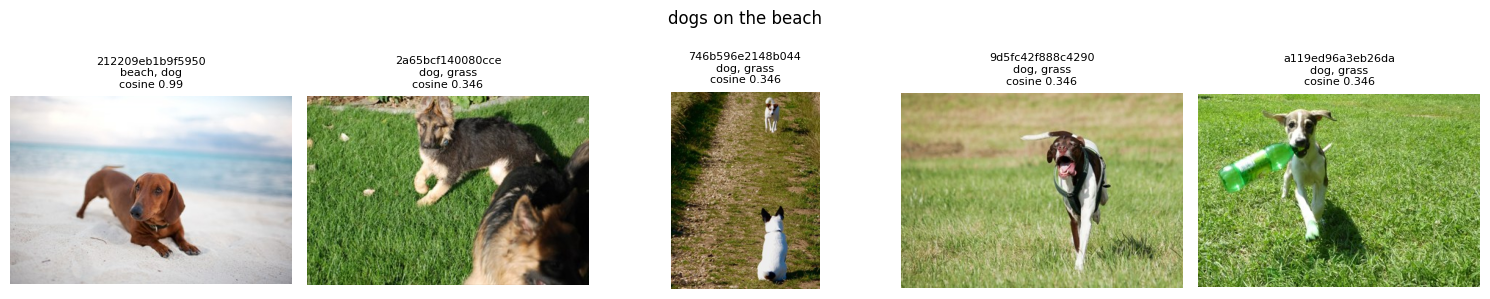

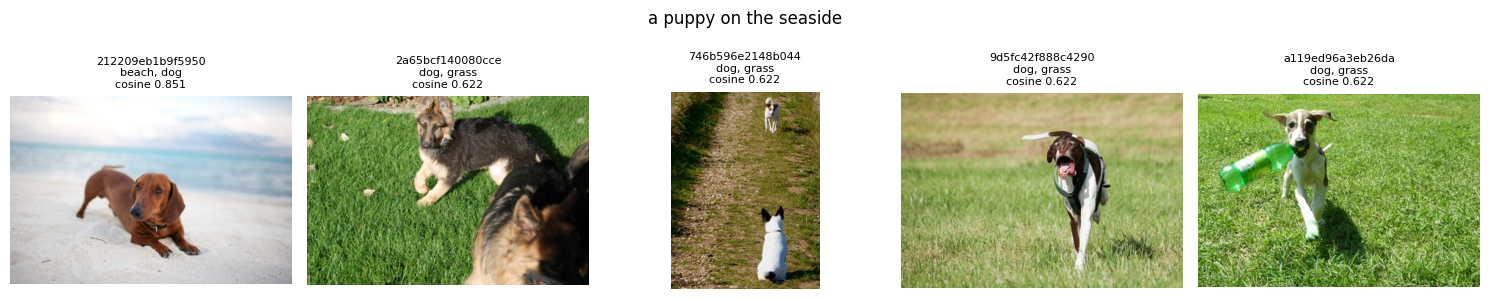

{'history': [{'train_loss': 7.034556025093738, 'train_token_accuracy': 0.13464696285264902, 'validation_loss': 6.402781687859322, 'validation_token_accuracy': 0.14308426064129665}, {'train_loss': 5.849178390452035, 'train_token_accuracy': 0.16167214023969867, 'validation_loss': 5.8511182069399394, 'validation_token_accuracy': 0.20000000111817934}, {'train_loss': 5.113771821445106, 'train_token_accuracy': 0.25171045381443286, 'validation_loss': 5.446630244414265, 'validation_token_accuracy': 0.24356120875984763}, {'train_loss': 4.402624487648522, 'train_token_accuracy': 0.3409277507958839, 'validation_loss': 5.166783211075824, 'validation_token_accuracy': 0.2756756732355809}, {'train_loss': 3.791061929799718, 'train_token_accuracy': 0.4094143389562603, 'validation_loss': 4.9586729792608555, 'validation_token_accuracy': 0.30620031519326574}, {'train_loss': 3.264421510742085, 'train_token_accuracy': 0.47735358105251613, 'validation_loss': 4.819946681600307, 'validation_token_accuracy': 0.

In [13]:
RUN_DEMOS = True  # Set True to run the examples.
if RUN_DEMOS:
    from hw3lib.experiment import train_retrieval, show_retrieval, train_translation, translate
    student, _ = load_submission("hw3.ipynb")
    retrieval_model, retrieval_info, retrieval_run = train_retrieval(student)
    print(retrieval_run)
    show_retrieval(student, retrieval_model, retrieval_info, "dogs on the beach")
    show_retrieval(student, retrieval_model, retrieval_info, "a puppy on the seaside")
    translation_model, translation_info, translation_run = train_translation(student, epochs=25)
    print(translation_run)
    for english, spanish in translation_info['raw']['validation'][:5]:
        print("English:", english)
        print("Reference:", spanish)
        print("Generated:", translate(student, translation_model, translation_info, english))